# Notebook 04 ? ??nh gi?, So s?nh M? h?nh & Ph?n t?ch l?i (Evaluation & QA)

- **Ng??i th?c hi?n:** Ph? ??ng Nguy?n Huynh (Th?nh vi?n 4 ? `nguyenhuy/evaluation-qa`)
- **M?c ti?u:** Ki?m tra ch?ng Data Leakage, ki?m ch?ng c?ng th?c metric (k? c? chia cho 0), so s?nh 3 ch? ?? (`Rule-only`, `Statistics-only`, `Combined`) c?ng `Majority Baseline` tr?n t?p `data/test.csv`, v? bi?u ?? tr?c quan v? ph?n t?ch chi ti?t c?c ca d? ?o?n sai.


## 1. Import th? vi?n & h?m l?i t? `src/`


In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import load_emails_from_csv
from src.rules import load_rules
from src.statistics import load_statistics, train_statistics
from src.classifier import load_settings, classify_email
from src.evaluation import (
    evaluate,
    evaluate_majority_baseline,
    check_data_leakage,
    export_evaluation_json,
)

plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", context="notebook")

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Kh?i t?o m?i tr??ng ??nh gi? th?nh c?ng! PROJECT_ROOT =", PROJECT_ROOT)


Kh?i t?o m?i tr??ng ??nh gi? th?nh c?ng! PROJECT_ROOT = D:\spam-emails-team


## 2. Ki?m tra ch?ng r? r? d? li?u (Data Leakage Audit ? Test T13)


In [2]:
train_emails, _ = load_emails_from_csv(str(PROJECT_ROOT / "data/train.csv"), require_label=True)
val_emails, _ = load_emails_from_csv(str(PROJECT_ROOT / "data/validation.csv"), require_label=True)
test_emails, _ = load_emails_from_csv(str(PROJECT_ROOT / "data/test.csv"), require_label=True)

leakage_report = check_data_leakage(train_emails, val_emails, test_emails)
print("B?o c?o ki?m tra Data Leakage:", json.dumps(leakage_report, indent=2, ensure_ascii=False))
assert not leakage_report["has_leakage"], "C?NH B?O: Ph?t hi?n tr?ng l?p d? li?u xuy?n t?p!"
print("PASS (T13): 0 b?n ghi tr?ng l?p gi?a train, validation v? test.")


B?o c?o ki?m tra Data Leakage: {
  "has_leakage": false,
  "overlap_counts": {
    "train_val": 0,
    "train_test": 0,
    "val_test": 0
  },
  "overlap_ids": {
    "train_val": [],
    "train_test": [],
    "val_test": []
  }
}
PASS (T13): 0 b?n ghi tr?ng l?p gi?a train, validation v? test.


## 3. Ki?m ch?ng c?ng th?c t?nh Metric & x? l? chia cho 0 (Test T12)


In [3]:
y_true_sample = ["spam"] * 38 + ["ham"] * 37
y_pred_sample = ["spam"] * 32 + ["ham"] * 6 + ["spam"] * 3 + ["ham"] * 34
sample_res = evaluate(y_true_sample, y_pred_sample)
assert (sample_res["tp"], sample_res["tn"], sample_res["fp"], sample_res["fn"]) == (32, 34, 3, 6)
assert round(sample_res["accuracy"], 4) == 0.8800

zero_res = evaluate(["ham", "ham"], ["ham", "ham"])
assert zero_res["precision"] == 0.0 and len(zero_res["warnings"]) > 0
print("PASS (T12): C?ng th?c metric v? x? l? chia cho 0 ho?t ??ng ch?nh x?c!")
print("C?nh b?o m?u khi m?u s? = 0:", zero_res["warnings"])


PASS (T12): C?ng th?c metric v? x? l? chia cho 0 ho?t ??ng ch?nh x?c!
C?nh b?o m?u khi m?u s? = 0: ['Precision không xác định do mẫu số bằng 0 (trả về 0.0).', 'Recall không xác định do mẫu số bằng 0 (trả về 0.0).', 'F1 không xác định do mẫu số bằng 0 (trả về 0.0).']


## 4. ??nh gi? & So s?nh 4 m? h?nh tr?n t?p Test ??c l?p (Test T15)


In [4]:
settings = load_settings(str(PROJECT_ROOT / "config/settings.json"))
rules = load_rules(str(PROJECT_ROOT / "config/rules.json"))
stats_path = PROJECT_ROOT / "data/processed/keyword_stats.json"
stats_model = load_statistics(str(stats_path)) if stats_path.is_file() else train_statistics(train_emails)

def get_predictions_df(csv_path: Path, emails: list) -> pd.DataFrame:
    if csv_path.is_file():
        return pd.read_csv(csv_path)
    recs = []
    for em in emails:
        r_res = classify_email(em, "rule_only", rules, stats_model, settings)
        s_res = classify_email(em, "statistics_only", rules, stats_model, settings)
        c_res = classify_email(em, "combined", rules, stats_model, settings)
        recs.append({
            "email_id": em.email_id,
            "label": em.label,
            "label_num": 1 if em.label == "spam" else 0,
            "rule_score": c_res.rule_score,
            "stat_score": c_res.stat_score,
            "combined_score": c_res.total_score,
            "pred_rule": r_res.prediction,
            "pred_stat": s_res.prediction,
            "pred_combined": c_res.prediction,
            "matched_rules": "; ".join(f"{m.rule_id}:{m.pattern}({m.weight:+g})" for m in c_res.matched_rules),
            "top_keywords": "; ".join(f"{k.token}({k.weight:+.2f})" for k in c_res.top_keywords),
        })
    return pd.DataFrame(recs)

val_pred = get_predictions_df(PROJECT_ROOT / "outputs/hybrid_val_predictions.csv", val_emails)
test_pred = get_predictions_df(PROJECT_ROOT / "outputs/hybrid_test_predictions.csv", test_emails)

train_labels = [em.label for em in train_emails]
y_val = val_pred["label"].tolist()
y_test = test_pred["label"].tolist()

test_metrics = {
    "majority_baseline": evaluate_majority_baseline(train_labels, y_test),
    "rule_only": evaluate(y_test, test_pred["pred_rule"].tolist()),
    "statistics_only": evaluate(y_test, test_pred["pred_stat"].tolist()),
    "combined": evaluate(y_test, test_pred["pred_combined"].tolist()),
}

val_metrics = {
    "majority_baseline": evaluate_majority_baseline(train_labels, y_val),
    "rule_only": evaluate(y_val, val_pred["pred_rule"].tolist()),
    "statistics_only": evaluate(y_val, val_pred["pred_stat"].tolist()),
    "combined": evaluate(y_val, val_pred["pred_combined"].tolist()),
}

rows = []
display_names = {
    "majority_baseline": "Majority Baseline (lu?n ?o?n ham)",
    "rule_only": f"Rule-only (T = {settings['thresholds']['rule_only']})",
    "statistics_only": f"Statistics-only (T = {settings['thresholds']['statistics_only']})",
    "combined": f"Combined / Hybrid (T = {settings['thresholds']['combined']})",
}
for key, label_name in display_names.items():
    m = test_metrics[key]
    rows.append({
        "M? h?nh": label_name,
        "TP": m["tp"], "TN": m["tn"], "FP": m["fp"], "FN": m["fn"],
        "Accuracy (%)": round(m["accuracy"] * 100, 2),
        "Precision (%)": round(m["precision"] * 100, 2),
        "Recall (%)": round(m["recall"] * 100, 2),
        "F1-score (%)": round(m["f1"] * 100, 2),
        "FPR (%)": round(m["fpr"] * 100, 2),
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df)


,M? h?nh,TP,TN,FP,FN,Accuracy (%),Precision (%),Recall (%),F1-score (%),FPR (%)
0,Majority Baseline (lu?n ?o?n ham),0,38,0,37,50.67,0.00,0.00,0.00,0.00
1,Rule-only (T = 0.0),37,30,8,0,89.33,82.22,100.00,90.24,21.05
2,Statistics-only (T = -0.75),30,38,0,7,90.67,100.00,81.08,89.55,0.00
3,Combined / Hybrid (T = -0.75),33,37,1,4,93.33,97.06,89.19,92.96,2.63


## 5. Tr?c quan h?a k?t qu? (Confusion Matrix, So s?nh Metric & Ph?n b? ?i?m)


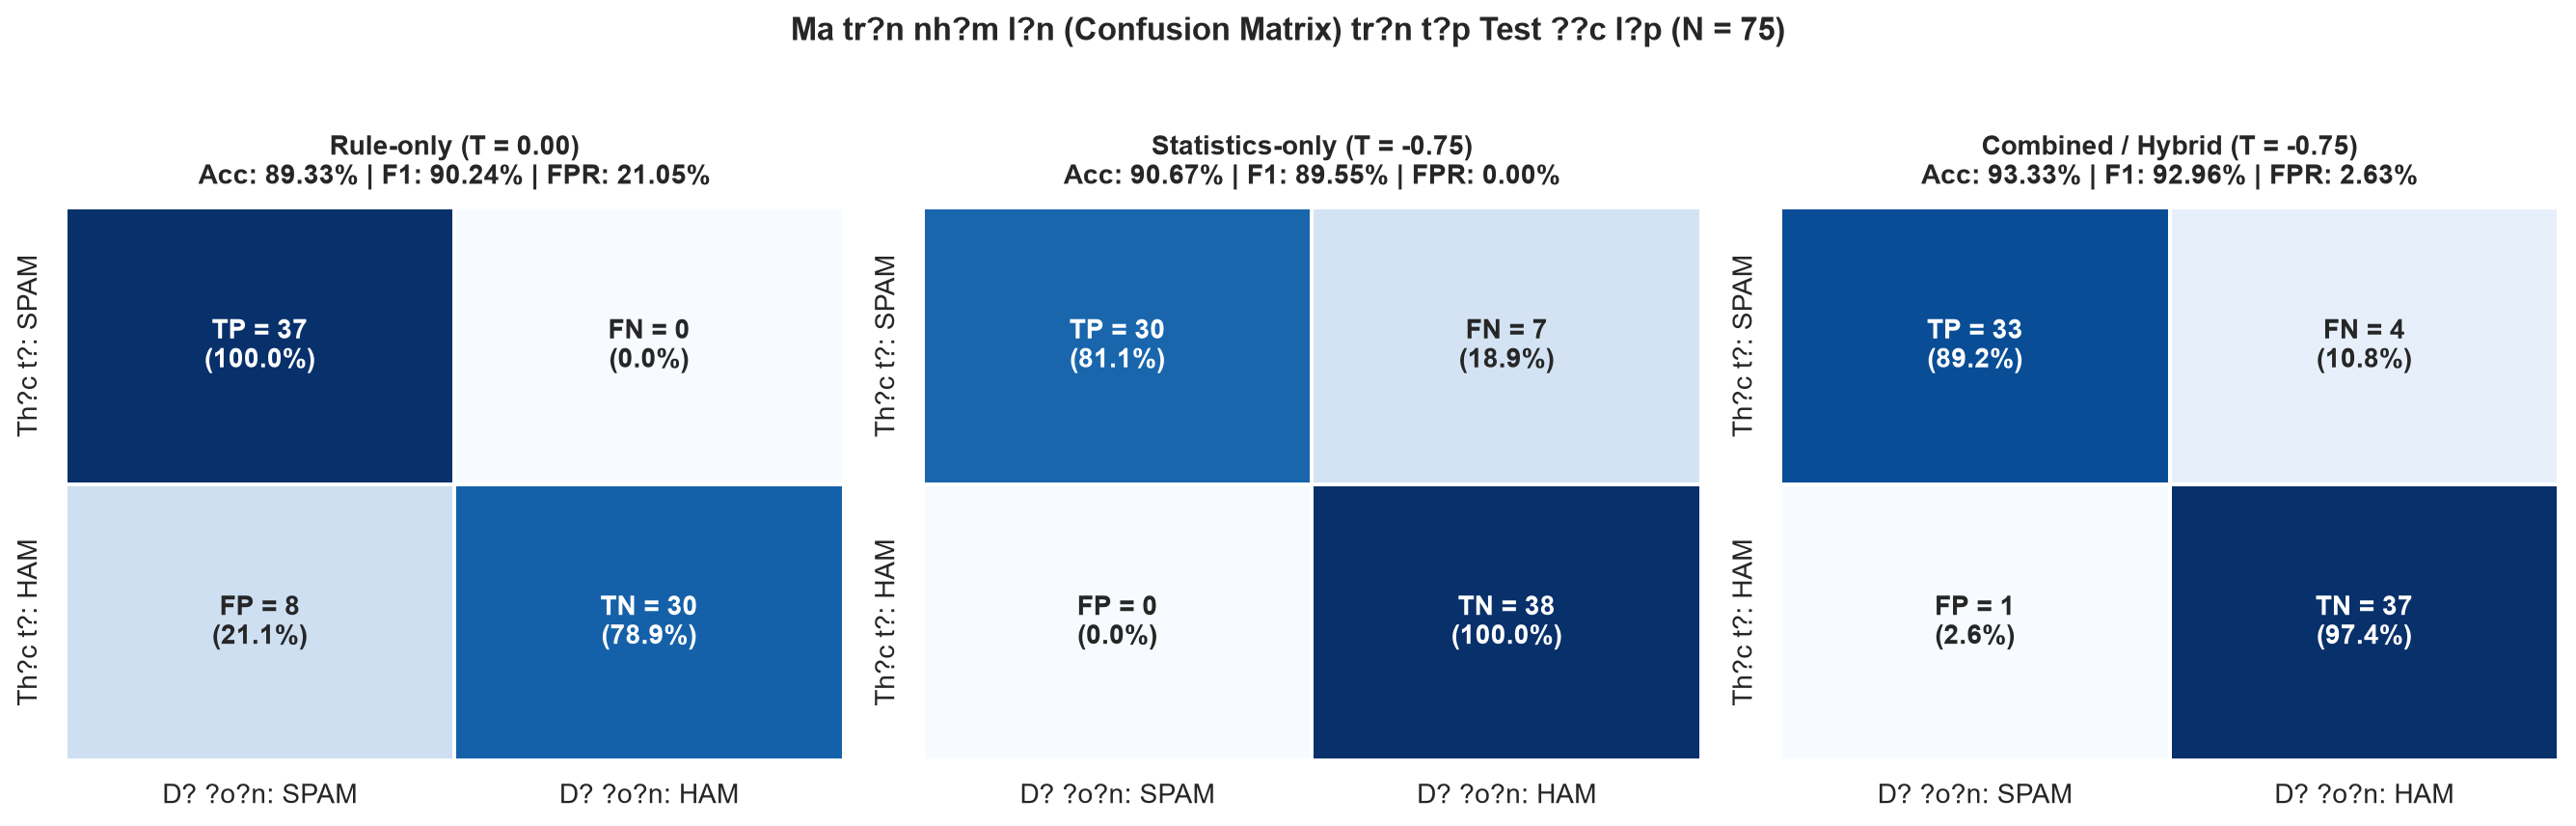

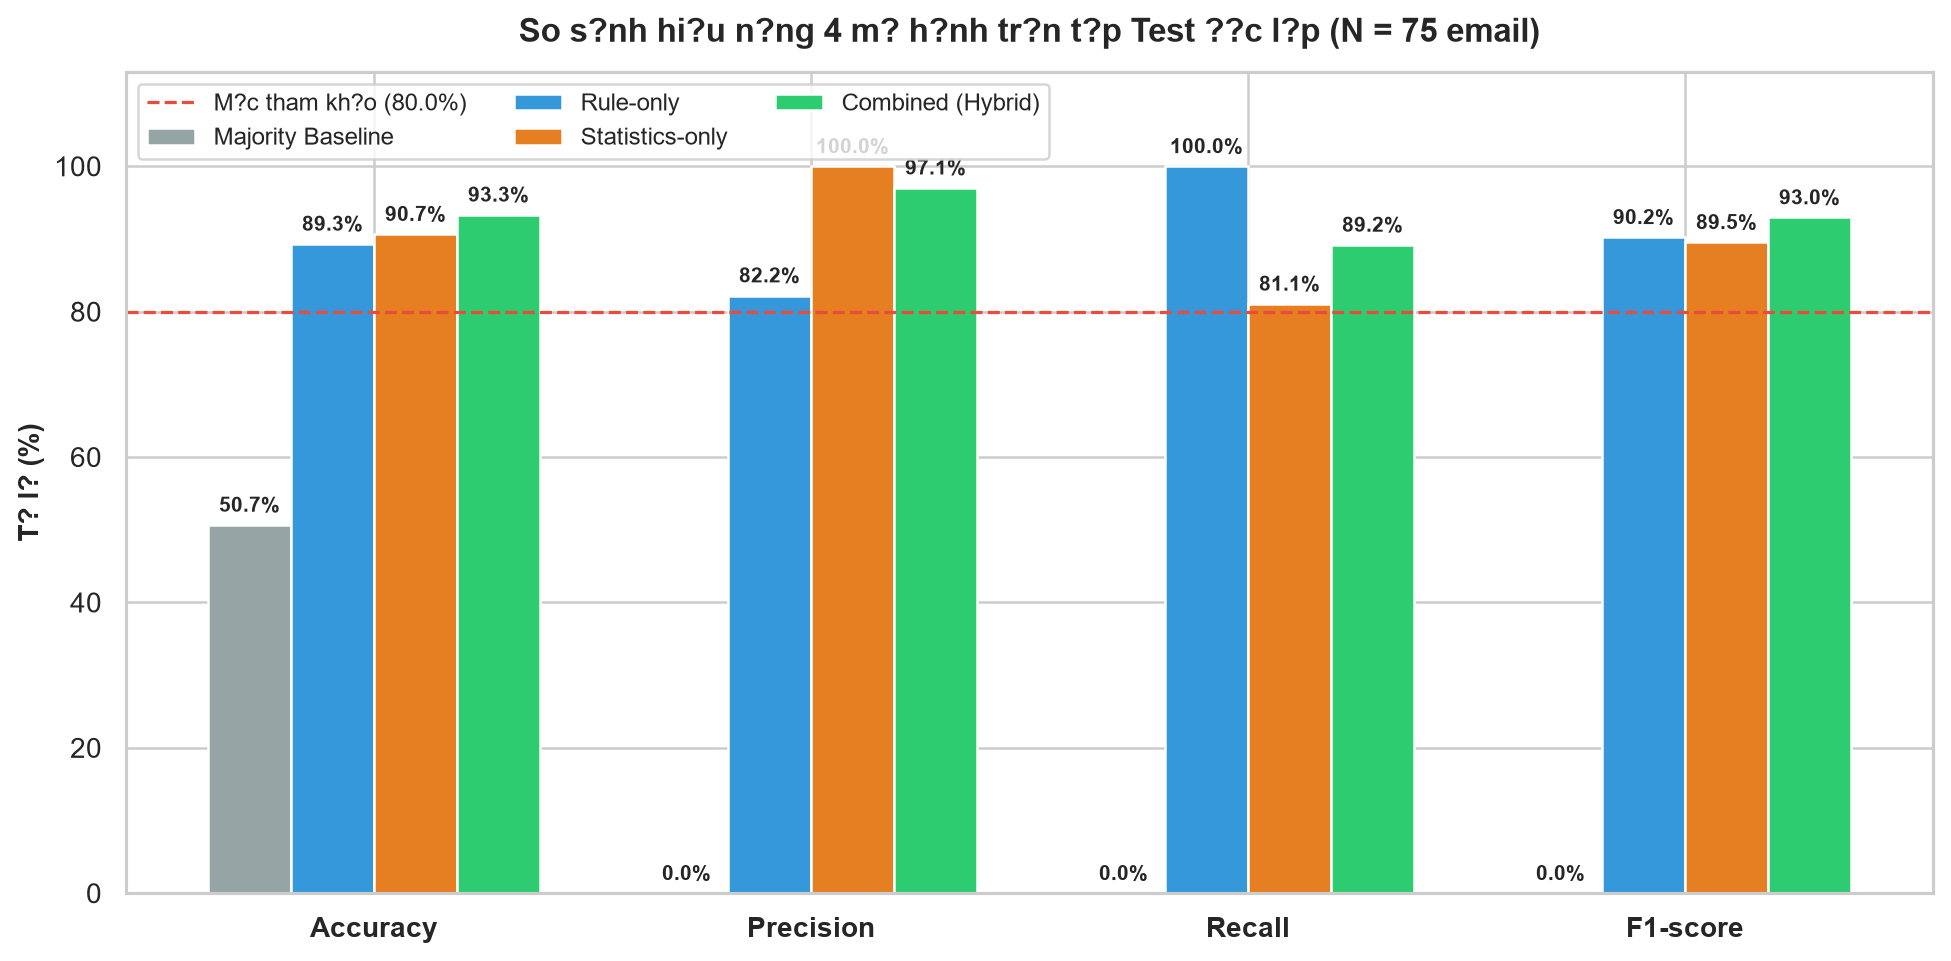

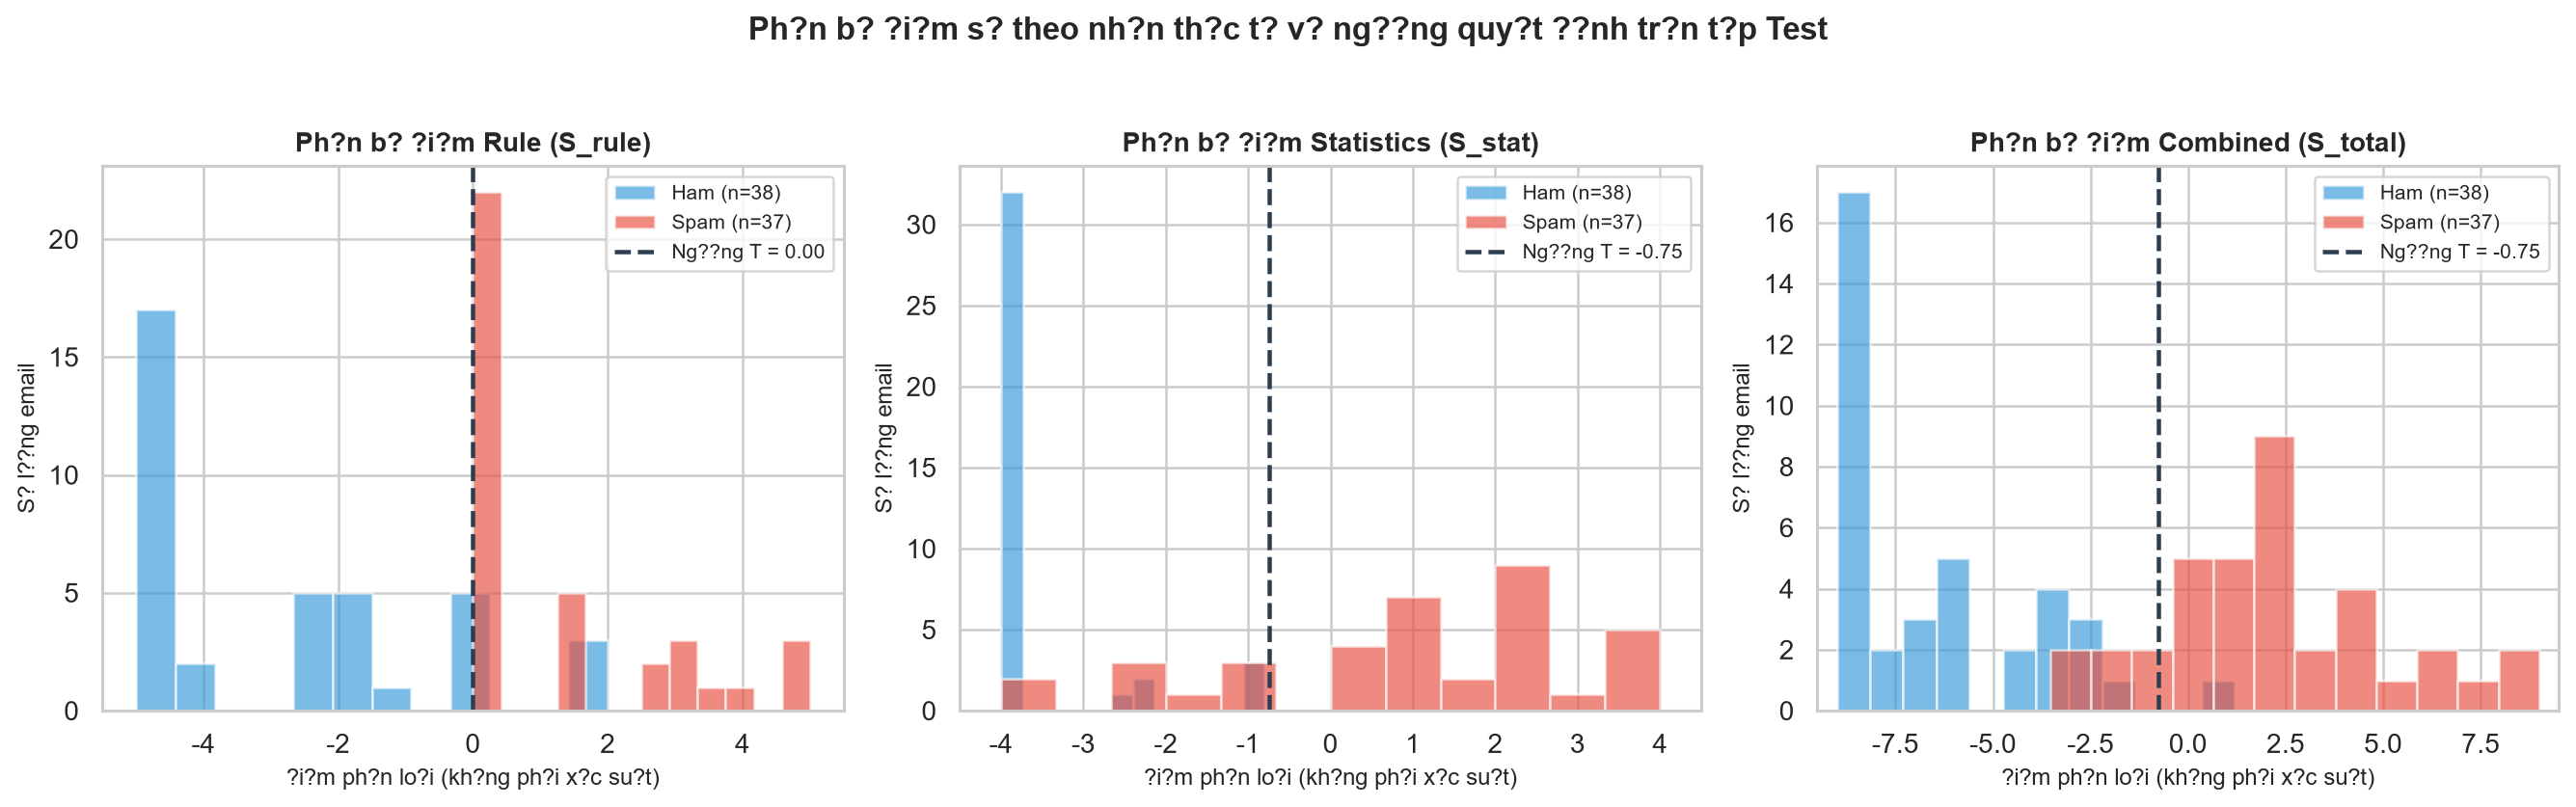

In [5]:
n_test_total = len(test_pred)
n_spam = max(int((test_pred["label"] == "spam").sum()), 1)
n_ham = max(int((test_pred["label"] == "ham").sum()), 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), dpi=180)
modes_info = [
    ("rule_only", f"Rule-only (T = {settings['thresholds']['rule_only']:.2f})"),
    ("statistics_only", f"Statistics-only (T = {settings['thresholds']['statistics_only']:.2f})"),
    ("combined", f"Combined / Hybrid (T = {settings['thresholds']['combined']:.2f})"),
]

for ax, (mode_key, title) in zip(axes, modes_info):
    m = test_metrics[mode_key]
    cm = np.array([[m["tp"], m["fn"]], [m["fp"], m["tn"]]])
    annot = np.array([
        [f"TP = {m['tp']}\n({m['tp']/n_spam*100:.1f}%)", f"FN = {m['fn']}\n({m['fn']/n_spam*100:.1f}%)"],
        [f"FP = {m['fp']}\n({m['fp']/n_ham*100:.1f}%)", f"TN = {m['tn']}\n({m['tn']/n_ham*100:.1f}%)"],
    ])
    sns.heatmap(
        cm, annot=annot, fmt="", cmap="Blues", cbar=False,
        xticklabels=["D? ?o?n: SPAM", "D? ?o?n: HAM"],
        yticklabels=["Th?c t?: SPAM", "Th?c t?: HAM"],
        annot_kws={"size": 11, "weight": "bold"},
        linewidths=1.5, linecolor="white", ax=ax,
    )
    ax.set_title(
        f"{title}\nAcc: {m['accuracy']*100:.2f}% | F1: {m['f1']*100:.2f}% | FPR: {m['fpr']*100:.2f}%",
        fontsize=11, fontweight="bold", pad=10,
    )

plt.suptitle(f"Ma tr?n nh?m l?n (Confusion Matrix) tr?n t?p Test ??c l?p (N = {n_test_total})", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_confusion_matrices.png", bbox_inches="tight", dpi=180)
plt.show()

model_labels = ["Majority Baseline", "Rule-only", "Statistics-only", "Combined (Hybrid)"]
model_keys = ["majority_baseline", "rule_only", "statistics_only", "combined"]
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_keys = ["accuracy", "precision", "recall", "f1"]

x = np.arange(len(metric_names))
width = 0.19
colors = ["#95a5a6", "#3498db", "#e67e22", "#2ecc71"]

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=180)
for idx, (m_key, m_label, color) in enumerate(zip(model_keys, model_labels, colors)):
    vals = [test_metrics[m_key][mk] * 100 for mk in metric_keys]
    bars = ax.bar(x + (idx - 1.5) * width, vals, width, label=m_label, color=color, edgecolor="white")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 1.2, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.axhline(80.0, color="#e74c3c", linestyle="--", linewidth=1.3, label="M?c tham kh?o (80.0%)")
ax.set_ylabel("T? l? (%)", fontsize=11, fontweight="bold")
ax.set_title(f"So s?nh hi?u n?ng 4 m? h?nh tr?n t?p Test ??c l?p (N = {n_test_total} email)", fontsize=13, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=11, fontweight="bold")
ax.set_ylim(0, 113)
ax.legend(loc="upper left", ncol=3, frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_mode_comparison.png", bbox_inches="tight", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=180)
score_specs = [
    ("rule_score", "rule_only", "Ph?n b? ?i?m Rule (S_rule)", (-5.5, 5.5)),
    ("stat_score", "statistics_only", "Ph?n b? ?i?m Statistics (S_stat)", (-4.5, 4.5)),
    ("combined_score", "combined", "Ph?n b? ?i?m Combined (S_total)", (-9.5, 9.5)),
]
for ax, (col, mode_key, title, xlim) in zip(axes, score_specs):
    thresh = settings["thresholds"][mode_key]
    ax.hist(test_pred[test_pred["label"] == "ham"][col], bins=12, alpha=0.65, color="#3498db", label=f"Ham (n={n_ham})", edgecolor="white")
    ax.hist(test_pred[test_pred["label"] == "spam"][col], bins=12, alpha=0.65, color="#e74c3c", label=f"Spam (n={n_spam})", edgecolor="white")
    ax.axvline(thresh, color="#2c3e50", linestyle="--", linewidth=1.8, label=f"Ng??ng T = {thresh:.2f}")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("?i?m ph?n lo?i (kh?ng ph?i x?c su?t)", fontsize=9.5)
    ax.set_ylabel("S? l??ng email", fontsize=9.5)
    ax.set_xlim(xlim)
    ax.legend(fontsize=8.5, loc="upper right")

plt.suptitle("Ph?n b? ?i?m s? theo nh?n th?c t? v? ng??ng quy?t ??nh tr?n t?p Test", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_score_distributions.png", bbox_inches="tight", dpi=180)
plt.show()


## 6. Ph?n t?ch l?i (Error Analysis) & Xu?t `outputs/evaluation_report.json`


In [6]:
test_raw_df = pd.read_csv(PROJECT_ROOT / "data/test.csv")[["email_id", "subject"]]
merged_test = test_pred.merge(test_raw_df, on="email_id", how="left")

fp_df = merged_test[(merged_test["label"] == "ham") & (merged_test["pred_combined"] == "spam")]
fn_df = merged_test[(merged_test["label"] == "spam") & (merged_test["pred_combined"] == "ham")]

print(f"=== FALSE POSITIVES (Ham ?o?n nh?m th?nh Spam): {len(fp_df)} ca ===")
display(fp_df[["email_id", "subject", "rule_score", "stat_score", "combined_score", "matched_rules", "top_keywords"]])

print(f"\n=== FALSE NEGATIVES (Spam b? b? s?t th?nh Ham): {len(fn_df)} ca ===")
display(fn_df[["email_id", "subject", "rule_score", "stat_score", "combined_score", "matched_rules", "top_keywords"]])

report_payload = {
    "author": "Ph? ??ng Nguy?n Huynh",
    "dataset_summary": {
        "train_total": len(train_emails),
        "validation_total": len(val_emails),
        "test_total": len(test_emails),
        "test_spam": int((test_pred["label"] == "spam").sum()),
        "test_ham": int((test_pred["label"] == "ham").sum()),
        "positive_class": "spam",
    },
    "thresholds": settings["thresholds"],
    "leakage_audit": leakage_report,
    "validation_metrics": val_metrics,
    "test_metrics": test_metrics,
    "error_analysis": {
        "combined_false_positives": fp_df[["email_id", "subject", "rule_score", "stat_score", "combined_score", "matched_rules", "top_keywords"]].fillna("").to_dict(orient="records"),
        "combined_false_negatives": fn_df[["email_id", "subject", "rule_score", "stat_score", "combined_score", "matched_rules", "top_keywords"]].fillna("").to_dict(orient="records"),
    },
}

out_json = export_evaluation_json(report_payload, str(PROJECT_ROOT / "outputs/evaluation_report.json"))
print("?? xu?t b?o c?o JSON th?nh c?ng t?i:", out_json)


=== FALSE POSITIVES (Ham ?o?n nh?m th?nh Spam): 1 ca ===


,email_id,subject,rule_score,stat_score,combined_score,matched_rules,top_keywords
38,E0464,fw : candle lighting,2.0,-0.8,1.2,R012:guaranteed(+2.0),2001(-2.00); guaranteed(+2.00); pm(-2.00); smi...



=== FALSE NEGATIVES (Spam b? b? s?t th?nh Ham): 4 ca ===


,email_id,subject,rule_score,stat_score,combined_score,matched_rules,top_keywords
7,E0433,never see a doctor again to get the medocation...,0.0,-2.1986,-2.1986,NaN,03(-2.00); doctor(+2.00); pm(-2.00); tell(-1.7...
21,E0447,"coca cola , mbna america , nascar partner with...",1.5,-4.0000,-2.5000,R016:investment(+1.5),02(-2.00); 03(-2.00); 04(-2.00); 08(-2.00); ag...
35,E0461,quality rx meds supplier goode,0.0,-2.4000,-2.4000,NaN,cc(-2.00); ic(-2.00); ls(-2.00); meds(+2.00); ...
66,E0492,today ' s daily sales for angelo only,0.0,-3.5373,-3.5373,NaN,daily(-2.00); contract(-1.83); mary(-1.79); ag...


?? xu?t b?o c?o JSON th?nh c?ng t?i: D:\spam-emails-team\outputs\evaluation_report.json
